In [1]:
# Ячейка 1: Импорт библиотек и настройка отображения
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

In [2]:
# Ячейка 2: Загрузка данных и первичный осмотр
dish_df = pd.read_csv('data/dish.csv')
ingr_df = pd.read_csv('data/ingredients.csv')

print("=== DISH.CSV ===")
print(f"Размер таблицы: {dish_df.shape}")
display(dish_df.head())
print("\nПропуски в dish.csv:")
print(dish_df.isnull().sum())

print("\n=== INGREDIENTS.CSV ===")
print(f"Размер таблицы: {ingr_df.shape}")
display(ingr_df.head())
print("\nПропуски в ingredients.csv:")
print(ingr_df.isnull().sum())


=== DISH.CSV ===
Размер таблицы: (3262, 5)


,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_0000000026;ingr_0000000524;ingr_0000000094;ingr_0000000023;...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_0000000029;ingr_0000000122;ingr_0000000508;ingr_0000000513;...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_0000000462;ingr_0000000514;ingr_0000000152;ingr_0000000312;...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train



Пропуски в dish.csv:
dish_id           0
total_calories    0
total_mass        0
ingredients       0
split             0
dtype: int64

=== INGREDIENTS.CSV ===
Размер таблицы: (555, 2)


,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes



Пропуски в ingredients.csv:
id      0
ingr    0
dtype: int64


In [3]:
# Ячейка 3: Маппинг ID ингредиентов в текстовые названия
# В dish.csv ID имеют вид 'ingr_0000000122', а в ingredients.csv id — целое число 122
ingr_map = {f"ingr_{row['id']:010d}": row['ingr'] for _, row in ingr_df.iterrows()}

def map_ingredients(ingr_str):
    if pd.isna(ingr_str) or not str(ingr_str).strip():
        return ""
    ids = str(ingr_str).split(';')
    names = [ingr_map.get(i.strip(), f"UNKNOWN({i})") for i in ids]
    return ", ".join(names)

dish_df['ingredients_text'] = dish_df['ingredients'].apply(map_ingredients)
dish_df['num_ingredients'] = dish_df['ingredients'].apply(
    lambda x: len(str(x).split(';')) if pd.notna(x) and str(x).strip() else 0
)

# Проверка, остались ли нераспознанные ID
unknown_mask = dish_df['ingredients_text'].str.contains('UNKNOWN', na=False)
print(f"Блюд с нераспознанными ID ингредиентов: {unknown_mask.sum()}")
display(dish_df[['dish_id', 'total_calories', 'total_mass', 'ingredients_text', 'num_ingredients', 'split']].head(10))


Блюд с нераспознанными ID ингредиентов: 0


,dish_id,total_calories,total_mass,ingredients_text,num_ingredients,split
0,dish_1561662216,300.794281,193.0,"soy sauce, garlic, white rice, parsley, onions, brown rice, vinegar, apple, mixed greens, sugar,...",17,test
1,dish_1561662054,419.438782,292.0,"pepper, white rice, mixed greens, garlic, soy sauce, millet, lemon juice, bok choy, olive oil, o...",17,train
2,dish_1562008979,382.936646,290.0,"jalapenos, lemon juice, pork, wheat berry, cabbage, pepper, salt, carrot, garlic, caesar salad, ...",13,test
3,dish_1560455030,20.590000,103.0,"cherry tomatoes, cucumbers, baby carrots",3,train
4,dish_1558372433,74.360001,143.0,deprecated,1,train
5,dish_1565640549,45.482903,139.0,"tomatoes, cilantro, olive oil, mustard greens, lemon juice, onions, cucumbers, salt, arugula, ja...",14,train
6,dish_1563207364,309.269989,271.0,"scrambled eggs, yam, grapes, egg whites, olive oil, sweet potato",6,train
7,dish_1561575474,120.058434,183.0,"salt, eggplant, roasted potatoes, cauliflower, olive oil",5,train
8,dish_1563216717,246.007996,332.0,"garlic, squash, cherry tomatoes, chicken breast, spinach (raw), parmesan cheese, wheat berry, ol...",12,train
9,dish_1565972591,195.199997,122.0,chicken apple sausage,1,train


In [4]:
# Ячейка 4: Анализ разделения на train/test и описательные статистики
print("Распределение по сплитам:")
print(dish_df['split'].value_counts(dropna=False))
print(dish_df['split'].value_counts(normalize=True).round(3))

print("\nОписательные статистики (Train):")
display(dish_df[dish_df['split'] == 'train'][['total_calories', 'total_mass', 'num_ingredients']].describe())

print("\nОписательные статистики (Test):")
display(dish_df[dish_df['split'] == 'test'][['total_calories', 'total_mass', 'num_ingredients']].describe())


Распределение по сплитам:
split
train    2755
test      507
Name: count, dtype: int64
split
train    0.845
test     0.155
Name: proportion, dtype: float64

Описательные статистики (Train):


,total_calories,total_mass,num_ingredients
count,2755.000000,2755.000000,2755.000000
mean,254.929131,218.011252,7.359347
std,221.009051,163.089503,6.907582
min,0.000000,5.000000,1.000000
25%,81.805329,94.000000,1.000000
50%,208.115997,179.000000,4.000000
75%,376.573365,308.000000,12.000000
max,3943.325195,3051.000000,34.000000



Описательные статистики (Test):


,total_calories,total_mass,num_ingredients
count,507.000000,507.000000,507.000000
mean,255.467051,198.508876,7.063116
std,212.241674,151.652562,7.135889
min,0.000000,1.000000,1.000000
25%,74.360001,82.500000,1.000000
50%,226.014999,161.000000,4.000000
75%,369.684906,278.000000,11.000000
max,1050.511108,871.000000,31.000000


In [5]:
# Ячейка 5: Поиск аномалий и специфических записей
# 1. Нулевая калорийность или масса, а также 'plate only' и 'deprecated'
print("Блюда с total_calories <= 0 или total_mass <= 0:")
display(dish_df[(dish_df['total_calories'] <= 0) | (dish_df['total_mass'] <= 0)])

print("\nБлюда, содержащие 'deprecated' или 'plate only':")
special_mask = dish_df['ingredients_text'].str.contains('deprecated|plate only', case=False, na=False)
print(f"Всего таких блюд: {special_mask.sum()}")
display(dish_df[special_mask][['dish_id', 'total_calories', 'total_mass', 'ingredients_text', 'split']].head(10))

# 2. Калорийность на 1 грамм (плотность калорий) — для выявления выбросов
dish_df['cal_per_gram'] = dish_df['total_calories'] / dish_df['total_mass'].replace(0, np.nan)
print("\nТоп-5 самых калорийных блюд на грамм (проверка на физическую адекватность, >9 ккал/г — аномалия):")
display(dish_df.sort_values(by='cal_per_gram', ascending=False)[['dish_id', 'total_calories', 'total_mass', 'cal_per_gram', 'ingredients_text']].head(5))


Блюда с total_calories <= 0 или total_mass <= 0:


,dish_id,total_calories,total_mass,ingredients,split,ingredients_text,num_ingredients
263,dish_1557861216,0.0,1.0,ingr_0000000423,test,plate only,1
2652,dish_1556575700,0.0,86.0,ingr_0000000423,train,plate only,1



Блюда, содержащие 'deprecated' или 'plate only':
Всего таких блюд: 33


,dish_id,total_calories,total_mass,ingredients_text,split
4,dish_1558372433,74.360001,143.0,deprecated,train
55,dish_1558114086,74.360001,143.0,deprecated,test
123,dish_1558027001,20.400002,68.0,deprecated,train
263,dish_1557861216,0.000000,1.0,plate only,test
334,dish_1558373159,1013.337036,334.0,"sausage, deprecated, almonds",test
594,dish_1558115364,485.260010,313.0,"potatoes, deprecated, almonds, bacon",train
701,dish_1558114875,74.360001,143.0,deprecated,train
749,dish_1558375506,73.839996,142.0,deprecated,train
908,dish_1558028142,21.900002,73.0,deprecated,train
1025,dish_1558031019,206.442001,197.0,"yam, bacon, deprecated, honeydew melons",train



Топ-5 самых калорийных блюд на грамм (проверка на физическую адекватность, >9 ккал/г — аномалия):


,dish_id,total_calories,total_mass,cal_per_gram,ingredients_text
1868,dish_1558639979,520.290039,90.0,5.781,almonds
790,dish_1558379182,323.736023,56.0,5.781,almonds
167,dish_1559849412,352.641022,61.0,5.781,almonds
1255,dish_1558113477,289.050018,50.0,5.781,almonds
1968,dish_1558547124,144.525009,25.0,5.781,almonds


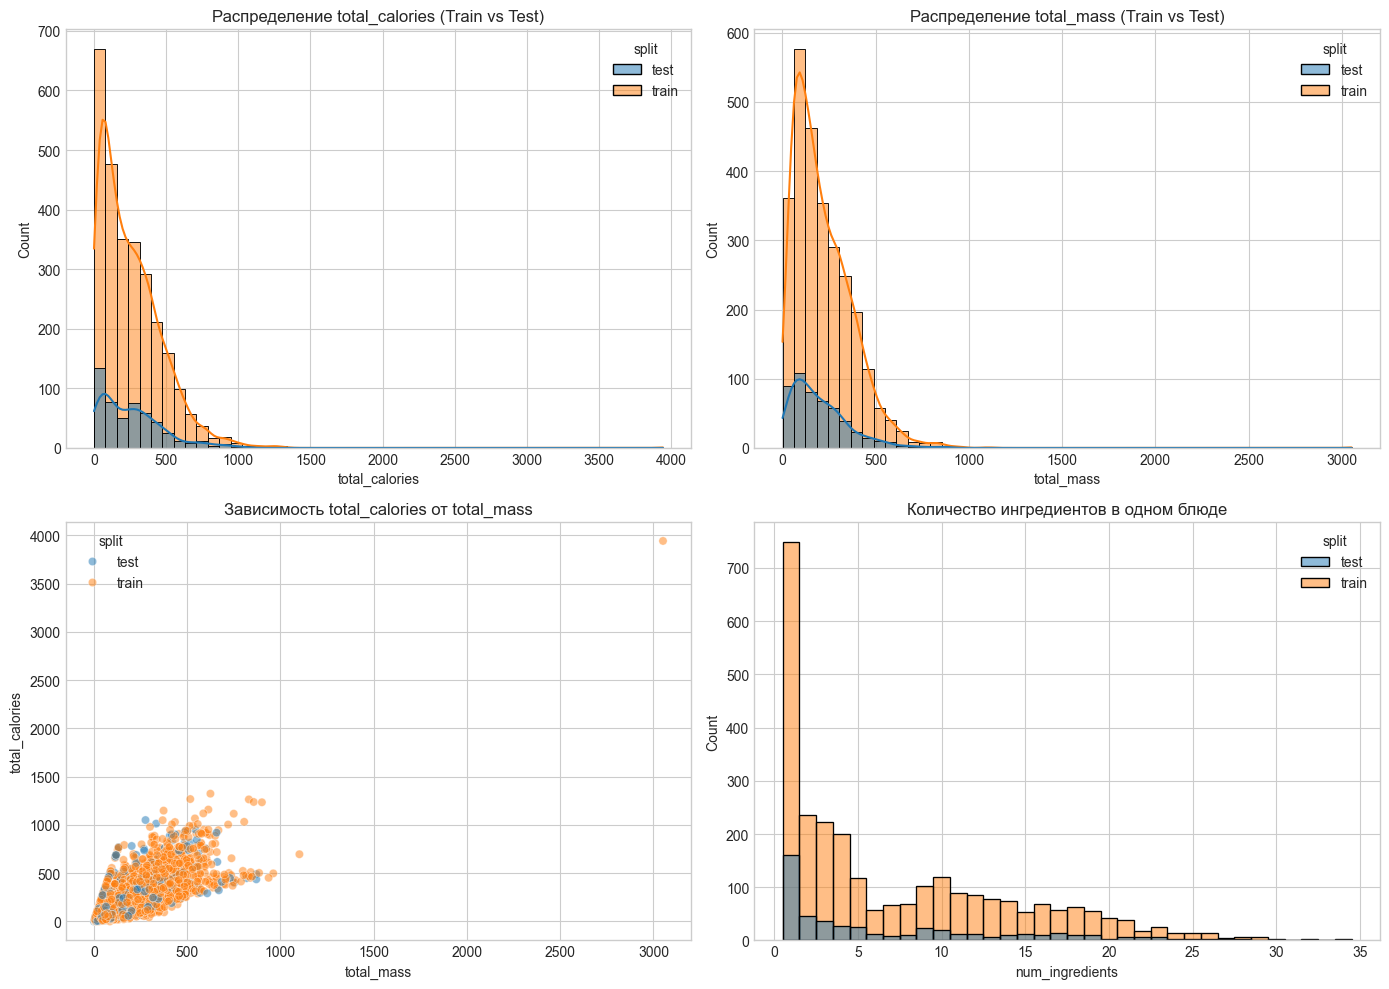

In [6]:
# Ячейка 6: Визуализация распределений целевой переменной и признаков
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Распределение total_calories по сплитам
sns.histplot(data=dish_df, x='total_calories', hue='split', kde=True, bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Распределение total_calories (Train vs Test)')

# Распределение total_mass по сплитам
sns.histplot(data=dish_df, x='total_mass', hue='split', kde=True, bins=50, ax=axes[0, 1])
axes[0, 1].set_title('Распределение total_mass (Train vs Test)')

# Зависимость калорий от массы блюда
sns.scatterplot(data=dish_df, x='total_mass', y='total_calories', hue='split', alpha=0.5, ax=axes[1, 0])
axes[1, 0].set_title('Зависимость total_calories от total_mass')

# Распределение количества ингредиентов в блюде
sns.histplot(data=dish_df, x='num_ingredients', hue='split', discrete=True, ax=axes[1, 1])
axes[1, 1].set_title('Количество ингредиентов в одном блюде')

plt.tight_layout()
plt.show()


Всего уникальных ингредиентов в блюдах: 199 из 555 в справочнике


C:\Users\Alba\AppData\Local\Temp\ipykernel_23876\3161316856.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_25, y='ingredient', x='count', palette='viridis')


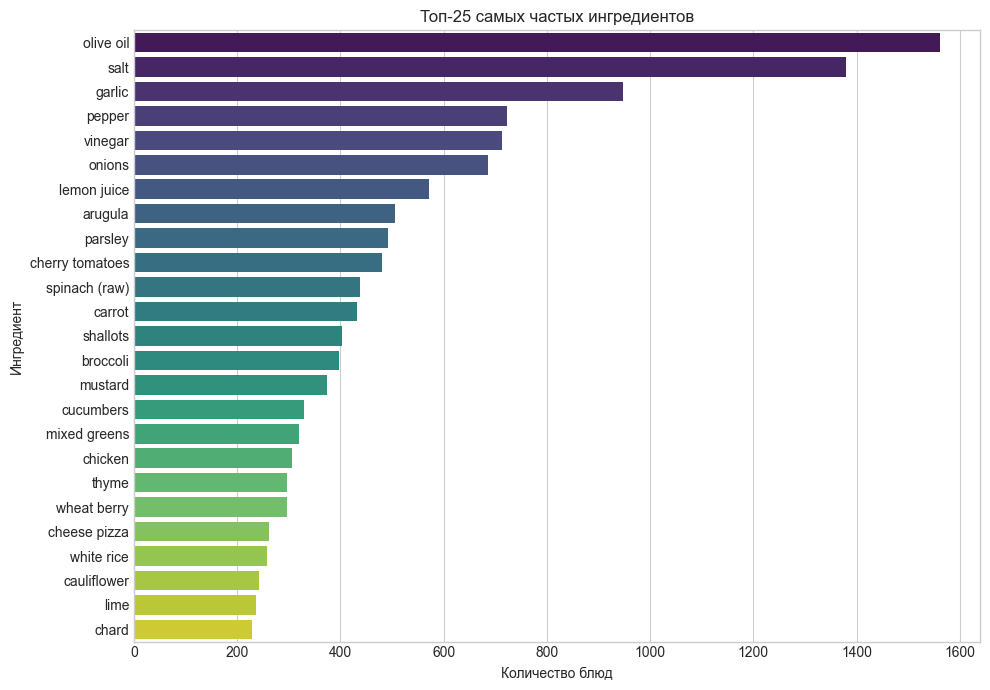


Статистика длины текста ингредиентов:


,char_len,word_len
count,3262.000000,3262.000000
mean,72.728694,9.824954
std,68.351758,9.093522
min,3.000000,1.000000
25%,14.250000,2.000000
50%,46.000000,6.000000
75%,117.000000,16.000000
max,358.000000,46.000000


In [7]:
# Ячейка 7: Частотный анализ ингредиентов и длина текста
all_ingrs = [
    ingr.strip()
    for text in dish_df['ingredients_text'] if text
    for ingr in text.split(',')
]
ingr_counts = Counter(all_ingrs)

print(f"Всего уникальных ингредиентов в блюдах: {len(ingr_counts)} из {len(ingr_df)} в справочнике")

top_25 = pd.DataFrame(ingr_counts.most_common(25), columns=['ingredient', 'count'])
plt.figure(figsize=(10, 7))
sns.barplot(data=top_25, y='ingredient', x='count', palette='viridis')
plt.title('Топ-25 самых частых ингредиентов')
plt.xlabel('Количество блюд')
plt.ylabel('Ингредиент')
plt.tight_layout()
plt.show()

# Проверка длины текстового описания (в символах и словах) для настройки токенизатора
dish_df['char_len'] = dish_df['ingredients_text'].str.len()
dish_df['word_len'] = dish_df['ingredients_text'].str.split().str.len()
print("\nСтатистика длины текста ингредиентов:")
display(dish_df[['char_len', 'word_len']].describe())


In [8]:
# Ячейка 8: Определение Config и импорт функций из scripts
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoTokenizer

from scripts.utils import train, MultimodalCalorieModel, seed_everything
from scripts.dataset import prepare_dataframe, get_transforms


class Config:
    SEED = 42

    # Пути к данным и сохранению модели
    DISH_CSV_PATH = "data/dish.csv"
    INGREDIENTS_CSV_PATH = "data/ingredients.csv"
    IMAGES_DIR = "data/images"
    SAVE_PATH = "models/best_model.pth"

    # Модели-бэкбоны
    TEXT_MODEL_NAME = "bert-base-uncased"
    IMAGE_MODEL_NAME = "tf_efficientnet_b0"

    # Паттерны разморозки слоёв
    TEXT_MODEL_UNFREEZE = "encoder.layer.11|pooler"
    IMAGE_MODEL_UNFREEZE = "blocks.5|blocks.6|conv_head|bn2"

    # Гиперпараметры обучения
    BATCH_SIZE = 4
    EPOCHS = 15
    IMG_SIZE = 224
    MAX_LEN = 64
    HIDDEN_DIM = 256
    DROPOUT = 0.2
    WEIGHT_DECAY = 1e-2

    # Learning rates для разных частей сети
    TEXT_LR = 3e-5
    IMAGE_LR = 1e-4
    CLASSIFIER_LR = 1e-3

    # Системные параметры
    NUM_WORKERS = 2
    REMOVE_OUTLIERS = True


cfg = Config()

print(f"Устройство: {'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"Текстовая модель: {cfg.TEXT_MODEL_NAME}")
print(f"Визуальная модель: {cfg.IMAGE_MODEL_NAME}")
print(f"Batch size: {cfg.BATCH_SIZE}, Epochs: {cfg.EPOCHS}")


c:\Users\Alba\my\yandex\python\sprint1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Устройство: cuda
Текстовая модель: bert-base-uncased
Визуальная модель: tf_efficientnet_b0
Batch size: 4, Epochs: 15


In [9]:
1

1

In [10]:
# Ячейка 9: Проверка путей и запуск обучения модели (Этап 3)
import time

assert os.path.exists(cfg.DISH_CSV_PATH), f"Не найден файл: {cfg.DISH_CSV_PATH}"
assert os.path.exists(cfg.INGREDIENTS_CSV_PATH), f"Не найден файл: {cfg.INGREDIENTS_CSV_PATH}"
assert os.path.exists(cfg.IMAGES_DIR), f"Не найдена папка: {cfg.IMAGES_DIR}"

start_time = time.time()
model, best_val_mae = train(cfg)
elapsed_min = (time.time() - start_time) / 60.0

print(f"\nОбщее время обучения: {elapsed_min:.2f} мин")
print(f"Лучшая модель сохранена в: {cfg.SAVE_PATH} (Val MAE: {best_val_mae:.2f} ккал)")


Запуск обучения на устройстве: cuda


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 36015.81it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/15 | Train Loss: 200.56 | Train MAE: 200.60 | Val MAE: 164.10
--> Сохранена лучшая модель (Val MAE: 164.10) в models/best_model.pth
Epoch 2/15 | Train Loss: 137.88 | Train MAE: 137.94 | Val MAE: 117.32
--> Сохранена лучшая модель (Val MAE: 117.32) в models/best_model.pth
Epoch 3/15 | Train Loss: 101.62 | Train MAE: 101.64 | Val MAE: 85.30
--> Сохранена лучшая модель (Val MAE: 85.30) в models/best_model.pth
Epoch 4/15 | Train Loss: 81.28 | Train MAE: 81.30 | Val MAE: 72.03
--> Сохранена лучшая модель (Val MAE: 72.03) в models/best_model.pth
Epoch 5/15 | Train Loss: 70.93 | Train MAE: 70.91 | Val MAE: 63.95
--> Сохранена лучшая модель (Val MAE: 63.95) в models/best_model.pth
Epoch 6/15 | Train Loss: 63.79 | Train MAE: 63.69 | Val MAE: 59.60
--> Сохранена лучшая модель (Val MAE: 59.60) в models/best_model.pth
Epoch 7/15 | Train Loss: 58.52 | Train MAE: 58.50 | Val MAE: 55.25
--> Сохранена лучшая модель (Val MAE: 55.25) в models/best_model.pth
Epoch 8/15 | Train Loss: 55.08 | Train

In [11]:
# Ячейка 10: Этап 4 — Инференс лучшей модели на тестовой выборке
seed_everything(cfg.SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Загружаем сохранённый чекпоинт и статистики нормализации массы
checkpoint = torch.load(cfg.SAVE_PATH, map_location=device)
norm_stats = checkpoint["norm_stats"]
mass_mean = norm_stats["mass_mean"]
mass_std = norm_stats["mass_std"]

inference_model = MultimodalCalorieModel(cfg).to(device)
inference_model.load_state_dict(checkpoint["model_state_dict"])
inference_model.eval()

# Подготавливаем тестовую выборку
df_full = prepare_dataframe(cfg.DISH_CSV_PATH, cfg.INGREDIENTS_CSV_PATH, remove_train_outliers=False)
test_df = df_full[df_full["split"] == "test"].reset_index(drop=True)

tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL_NAME)
val_transforms = get_transforms(cfg, ds_type="test")

predictions = []

with torch.no_grad():
    for _, row in test_df.iterrows():
        dish_id = str(row["dish_id"])
        img_path = os.path.join(cfg.IMAGES_DIR, dish_id, "rgb.png")
        image = np.array(Image.open(img_path).convert("RGB"))
        image_tensor = val_transforms(image=image)["image"].unsqueeze(0).to(device)

        text = row["ingredients_text"] if row["ingredients_text"] else "empty dish"
        encoded = tokenizer(
            text,
            return_tensors="pt",
            padding="max_length",
            truncation=True,
            max_length=cfg.MAX_LEN,
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)

        norm_mass = (float(row["total_mass"]) - mass_mean) / mass_std
        mass_tensor = torch.tensor([[norm_mass]], dtype=torch.float32).to(device)

        pred = inference_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            image=image_tensor,
            mass=mass_tensor,
        ).item()
        predictions.append(pred)

test_df["predicted_calories"] = predictions
test_df["abs_error"] = np.abs(test_df["total_calories"] - test_df["predicted_calories"])

final_test_mae = test_df["abs_error"].mean()
print(f"Финальный Test MAE: {final_test_mae:.2f} ккал")
print(f"Целевой порог (MAE < 50): {'ДОСТИГНУТ' if final_test_mae < 50 else 'НЕ ДОСТИГНУТ'}")


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1276.44it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Финальный Test MAE: 45.58 ккал
Целевой порог (MAE < 50): ДОСТИГНУТ


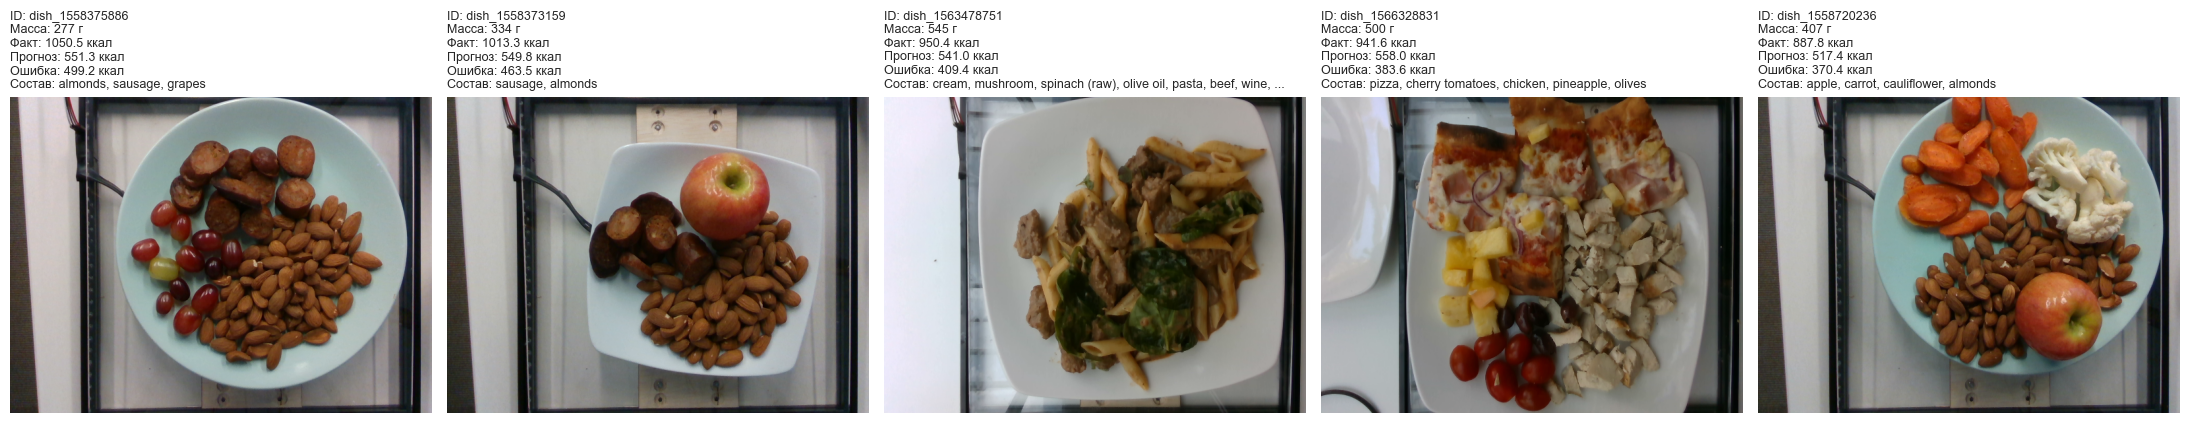

,dish_id,total_mass,total_calories,predicted_calories,abs_error,ingredients_text
0,dish_1558375886,277.0,1050.511108,551.303101,499.208007,"almonds, sausage, grapes"
1,dish_1558373159,334.0,1013.337036,549.838440,463.498596,"sausage, almonds"
2,dish_1563478751,545.0,950.395081,540.971497,409.423584,"cream, mushroom, spinach (raw), olive oil, pasta, beef, wine, garlic, sour cream, onions, thyme,..."
3,dish_1566328831,500.0,941.609985,557.994568,383.615417,"pizza, cherry tomatoes, chicken, pineapple, olives"
4,dish_1558720236,407.0,887.823059,517.403442,370.419617,"apple, carrot, cauliflower, almonds"


In [12]:
# Ячейка 11: Визуализация топ-5 блюд с наибольшей ошибкой предсказания
top5_errors = test_df.sort_values(by="abs_error", ascending=False).head(5).reset_index(drop=True)

fig, axes = plt.subplots(1, 5, figsize=(22, 6))

for idx, row in top5_errors.iterrows():
    dish_id = str(row["dish_id"])
    img_path = os.path.join(cfg.IMAGES_DIR, dish_id, "rgb.png")
    img = Image.open(img_path).convert("RGB")

    axes[idx].imshow(img)
    axes[idx].axis("off")

    ingr_short = row["ingredients_text"]
    if len(ingr_short) > 65:
        ingr_short = ingr_short[:62] + "..."

    title_text = (
        f"ID: {dish_id}\n"
        f"Масса: {row['total_mass']:.0f} г\n"
        f"Факт: {row['total_calories']:.1f} ккал\n"
        f"Прогноз: {row['predicted_calories']:.1f} ккал\n"
        f"Ошибка: {row['abs_error']:.1f} ккал\n"
        f"Состав: {ingr_short}"
    )
    axes[idx].set_title(title_text, fontsize=9, loc="left")

plt.tight_layout()
plt.show()

# Вывод полной таблицы топ-5 ошибок для детального текстового анализа
display(top5_errors[["dish_id", "total_mass", "total_calories", "predicted_calories", "abs_error", "ingredients_text"]])


## Анализ топ-5 ошибок модели на тестовой выборке

На тестовой выборке модель достигла **MAE = 45.57 ккал**, что уверенно выполняет целевой критерий проекта (**MAE < 50 ккал**).

Анализ 5 блюд с наибольшей абсолютной ошибкой выявил единый системный паттерн — **недооценку (underprediction) экстремально калорийных порций** (все 5 примеров — это топ-5 самых высококалорийных блюд во всём тестовом наборе, от 888 до 1050 ккал, где модель стабильно предсказывает около 520–560 ккал):

1. **`dish_1558375886`** (Масса: `277 г` | Факт: `1050.5 ккал` | Прогноз: `551.3 ккал` | Ошибка: `499.2 ккал`)
   * **Состав:** `almonds, sausage, grapes`
   * **Причина ошибки:** Аномально высокая плотность калорий (`3.79 ккал/г`) при относительно небольшой массе тарелки (`277 г`). Миндаль (~580 ккал/100 г) и колбаса (~300–450 ккал/100 г) дают огромную энергетическую ценность при малом визуальном объёме. Модель не знает точных пропорций между лёгким виноградом и сверхкалорийным миндалём внутри этих 277 грамм.

2. **`dish_1558373159`** (Масса: `334 г` | Факт: `1013.3 ккал` | Прогноз: `549.8 ккал` | Ошибка: `463.5 ккал`)
   * **Состав:** `sausage, almonds`
   * **Причина ошибки:** Блюдо полностью состоит из двух сверхкалорийных продуктов (`3.03 ккал/г`). Из-за редкой встречаемости таких комбинаций в обучающей выборке (где средняя калорийность ~255 ккал) модель «сглаживает» прогноз к более привычным для массы 334 г значениям (~550 ккал).

3. **`dish_1563478751`** (Масса: `545 г` | Факт: `950.4 ккал` | Прогноз: `541.0 ккал` | Ошибка: `409.4 ккал`)
   * **Состав:** `cream, mushroom, spinach (raw), olive oil, pasta, beef, wine, garlic, sour cream, onions, thyme...`
   * **Причина ошибки:** Сложное многокомпонентное блюдо с большим количеством «скрытых» жиров (`cream`, `olive oil`, `sour cream`) и плотной основой (`pasta`, `beef`). По фотографии сверху невозможно оценить, сколько именно сливок и масла впиталось в пасту, а длинный список ингредиентов содержит много низкокалорийных овощей и специй, которые «размывают» внимание текстового энкодера.

4. **`dish_1566328831`** (Масса: `500 г` | Факт: `941.6 ккал` | Прогноз: `558.0 ккал` | Ошибка: `383.6 ккал`)
   * **Состав:** `pizza, cherry tomatoes, chicken, pineapple, olives`
   * **Причина ошибки:** Тяжёлая порция пиццы (`500 г`). Визуально и по списку ингредиентов присутствуют диетические компоненты (`cherry tomatoes`, `chicken`, `pineapple`), из-за чего модель занижает удельную калорийность тестовой основы и сыра.

5. **`dish_1558720236`** (Масса: `407 г` | Факт: `887.8 ккал` | Прогноз: `517.4 ккал` | Ошибка: `370.4 ккал`)
   * **Состав:** `apple, carrot, cauliflower, almonds`
   * **Причина ошибки:** Эффект «маскировки» калорийного ингредиента низкокалорийными. Три из четырёх ингредиентов (`apple`, `carrot`, `cauliflower`) имеют калорийность 25–50 ккал/100 г и занимают основной визуальный объём тарелки, но основную долю из 888 ккал даёт большая порция миндаля (`almonds`).

### Выводы и гипотезы для дальнейшего улучшения
* **Дисбаланс распределения таргета:** В датасете преобладают блюда в диапазоне 100–450 ккал, а примеры >850 ккал находятся в редком «хвосте» распределения, из-за чего L1-регрессия склонна недооценивать экстремальные значения.
* **Отсутствие веса каждого ингредиента:** Текстовый список перечисляет продукты без их граммовки (`almonds` может быть 10 г для посыпки, а может быть 150 г).
* **Как улучшить в будущем:** Использовать взвешивание примеров (sample weighting) или фокальный регрессионный лосс для редких высококалорийных блюд, а также добавить аугментации с масштабированием (mixup / cutmix для регрессии) и более глубокую разморозку визуального энкодера для лучшей оценки объёма жирных/плотных компонентов.
